In [1]:
""" Generate personalized, data-driven recommendations from advanced machine learning models by applying domain-specific rules,
 collaborative filtering, or reinforcement learning techniques to maximize business impact."""

' Generate personalized, data-driven recommendations from advanced machine learning models by applying domain-specific rules,\n collaborative filtering, or reinforcement learning techniques to maximize business impact.'

In [2]:
# import required libraries
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

os.environ['LOKY_MAX_CPU_COUNT'] = '4'
warnings.filterwarnings('ignore')

In [3]:
# load and inspect dataset
df = pd.read_csv('global_pharmacy_sales_data.csv')
df['revenue'] = df['units_sold'] * df['unit_price']
df['segment_id'] = df['country'] + ' | ' + df['age_group']
print('Dataset shape:', df.shape)
print('Unique customer segments:', df['segment_id'].nunique())
print('Unique medicines:', df['medicine'].nunique())
df.head()

Dataset shape: (177990, 16)
Unique customer segments: 95
Unique medicines: 10


,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag,revenue,segment_id
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0,14884.64,UAE | 0-12
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1,28006.79,India | 26-45
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1,21339.48,UAE | 0-12
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0,17404.75,Sri Lanka | 0-12
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0,24929.64,Argentina | 26-45


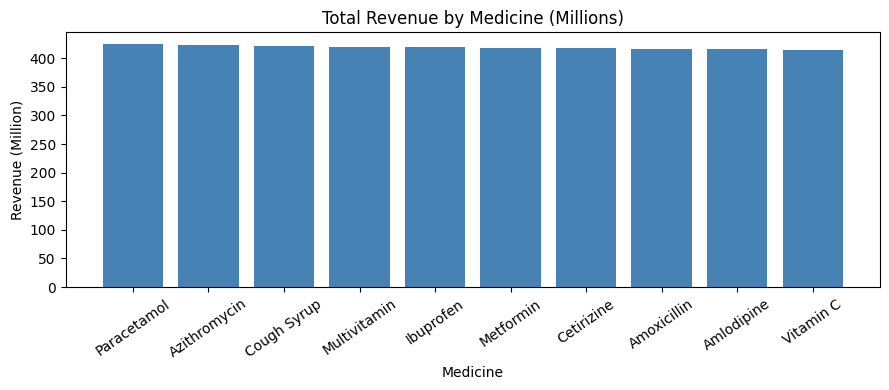

In [4]:
# plot total revenue by medicine
med_rev = df.groupby('medicine')['revenue'].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 4))
plt.bar(med_rev.index, med_rev.values / 1e6, color='steelblue')
plt.title('Total Revenue by Medicine (Millions)')
plt.xlabel('Medicine')
plt.ylabel('Revenue (Million)')
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

In [5]:
# build segment-medicine interaction matrix for collaborative filtering
interaction_matrix = df.pivot_table(
    index='segment_id',
    columns='medicine',
    values='revenue',
    aggfunc='mean'
).fillna(0)

norm_matrix = interaction_matrix.div(interaction_matrix.max(axis=1), axis=0)
print('Interaction matrix shape:', norm_matrix.shape)
norm_matrix.head()

Interaction matrix shape: (95, 10)


medicine,Amlodipine,Amoxicillin,Azithromycin,Cetirizine,Cough Syrup,Ibuprofen,Metformin,Multivitamin,Paracetamol,Vitamin C
segment_id,,,,,,,,,,
Argentina | 0-12,0.809923,0.833629,0.830207,0.829280,0.862833,0.837036,0.897309,0.929025,1.000000,0.901347
Argentina | 13-25,0.820705,0.986432,0.887596,0.864099,0.890787,0.862395,0.874582,1.000000,0.989420,0.971785
Argentina | 26-45,0.952702,0.858015,0.963850,0.944702,0.865195,0.883227,0.948221,0.863579,1.000000,0.917088
Argentina | 46-65,0.908091,0.933419,0.878548,1.000000,0.934423,0.929265,0.847072,0.822815,0.774320,0.762100
Argentina | 65+,0.995595,0.889874,1.000000,0.856708,0.988804,0.934070,0.828428,0.955934,0.984586,0.859910


In [6]:
# compute item similarity and svd collaborative filtering scores
item_sim = cosine_similarity(norm_matrix.T)
item_sim_df = pd.DataFrame(item_sim, index=norm_matrix.columns, columns=norm_matrix.columns)

svd = TruncatedSVD(n_components=4, random_state=42)
latent_segments = svd.fit_transform(norm_matrix)
reconstructed = np.dot(latent_segments, svd.components_)
cf_scores_df = pd.DataFrame(reconstructed, index=norm_matrix.index, columns=norm_matrix.columns)

recon_rmse = np.sqrt(mean_squared_error(norm_matrix.values, cf_scores_df.values))
print(f'SVD Reconstruction RMSE: {recon_rmse:.4f}')
print('Explained Variance Ratio sum:', round(svd.explained_variance_ratio_.sum(), 4))

SVD Reconstruction RMSE: 0.0466
Explained Variance Ratio sum: 0.5675


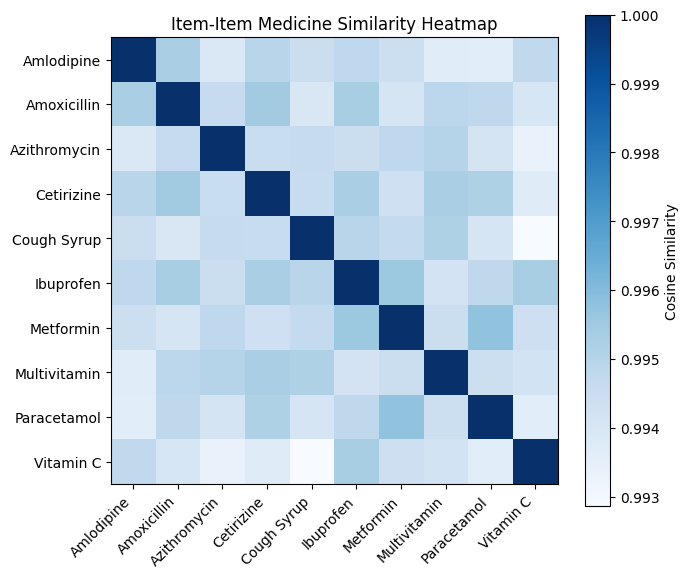

In [7]:
# visualize medicine similarity matrix from collaborative filtering
plt.figure(figsize=(7, 6))
plt.imshow(item_sim_df.values, cmap='Blues')
plt.colorbar(label='Cosine Similarity')
plt.xticks(range(len(item_sim_df.columns)), item_sim_df.columns, rotation=45, ha='right')
plt.yticks(range(len(item_sim_df.index)), item_sim_df.index)
plt.title('Item-Item Medicine Similarity Heatmap')
plt.tight_layout()
plt.show()

In [8]:
# train machine learning model to predict expected revenue impact
ml_df = df.sample(40000, random_state=42).copy()
cat_cols = ['region', 'country', 'category', 'medicine', 'age_group']
encoders = {}

for col in cat_cols:
    le = LabelEncoder()
    ml_df[col + '_enc'] = le.fit_transform(ml_df[col])
    encoders[col] = le

features = ['month', 'unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag',
            'region_enc', 'country_enc', 'category_enc', 'medicine_enc', 'age_group_enc']

X_train, X_test, y_train, y_test = train_test_split(
    ml_df[features], ml_df['revenue'], test_size=0.2, random_state=42
)

rf_rev = RandomForestRegressor(n_estimators=50, max_depth=12, random_state=42, n_jobs=-1)
rf_rev.fit(X_train, y_train)
preds = rf_rev.predict(X_test)

print('ML Revenue Predictor R2  :', round(r2_score(y_test, preds), 4))
print('ML Revenue Predictor RMSE:', round(np.sqrt(mean_squared_error(y_test, preds)), 2))

ML Revenue Predictor R2  : 0.951
ML Revenue Predictor RMSE: 5544.6


In [9]:
# apply reinforcement learning epsilon-greedy bandit to optimize medicine promotions
np.random.seed(42)
medicines = sorted(df['medicine'].unique())
med_rewards = {m: df[df['medicine'] == m]['revenue'].values for m in medicines}

n_rounds = 1500
epsilon = 0.1
counts = np.zeros(len(medicines))
values = np.zeros(len(medicines))
rl_rewards = []
random_rewards = []

for step in range(n_rounds):
    if np.random.rand() < epsilon:
        arm = np.random.randint(len(medicines))
    else:
        arm = int(np.argmax(values))

    med = medicines[arm]
    reward = np.random.choice(med_rewards[med])
    counts[arm] += 1
    values[arm] += (reward - values[arm]) / counts[arm]
    rl_rewards.append(reward)

    rand_med = medicines[np.random.randint(len(medicines))]
    random_rewards.append(np.random.choice(med_rewards[rand_med]))

rl_summary = pd.DataFrame({
    'medicine': medicines,
    'times_selected': counts.astype(int),
    'estimated_reward': np.round(values, 2)
}).sort_values('estimated_reward', ascending=False)

rl_summary

,medicine,times_selected,estimated_reward
2,Azithromycin,1242,25005.52
4,Cough Syrup,23,24362.63
1,Amoxicillin,93,23706.29
3,Cetirizine,23,21068.70
9,Vitamin C,9,20901.62
7,Multivitamin,24,20713.46
5,Ibuprofen,19,20635.79
8,Paracetamol,22,20294.45
0,Amlodipine,32,17562.62
6,Metformin,13,17242.10


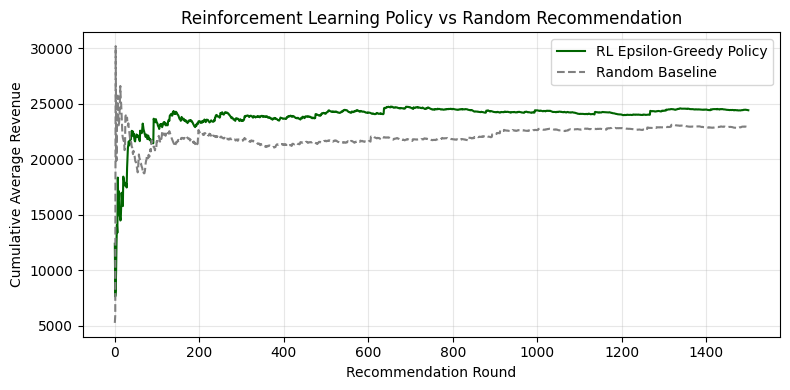

In [10]:
# plot reinforcement learning average reward vs random baseline
rl_cum_avg = np.cumsum(rl_rewards) / np.arange(1, n_rounds + 1)
rand_cum_avg = np.cumsum(random_rewards) / np.arange(1, n_rounds + 1)

plt.figure(figsize=(8, 4))
plt.plot(rl_cum_avg, label='RL Epsilon-Greedy Policy', color='darkgreen')
plt.plot(rand_cum_avg, label='Random Baseline', color='gray', linestyle='--')
plt.title('Reinforcement Learning Policy vs Random Recommendation')
plt.xlabel('Recommendation Round')
plt.ylabel('Cumulative Average Revenue')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
# combine collaborative filtering ml scores and domain-specific rules for recommendations
med_meta = df.groupby('medicine').agg(
    category=('category', 'first'),
    avg_price=('unit_price', 'mean'),
    avg_stock=('stock_level', 'mean'),
    avg_expiry=('expiry_days_remaining', 'mean'),
    avg_revenue=('revenue', 'mean')
).reset_index()

med_meta['rl_score'] = med_meta['medicine'].map(rl_summary.set_index('medicine')['estimated_reward'])
med_meta['rl_norm'] = med_meta['rl_score'] / med_meta['rl_score'].max()
med_meta['ml_norm'] = med_meta['avg_revenue'] / med_meta['avg_revenue'].max()

age_category_rules = {
    '0-12': {'Cough_Cold': 1.20, 'Vitamin': 1.15, 'Antipyretic': 1.10, 'Antibiotic': 1.00, 'Chronic': 0.70},
    '13-25': {'Vitamin': 1.20, 'Cough_Cold': 1.10, 'Antipyretic': 1.10, 'Antibiotic': 1.00, 'Chronic': 0.80},
    '26-45': {'Vitamin': 1.15, 'Antipyretic': 1.10, 'Antibiotic': 1.05, 'Cough_Cold': 1.05, 'Chronic': 1.00},
    '46-65': {'Chronic': 1.25, 'Vitamin': 1.10, 'Antipyretic': 1.00, 'Antibiotic': 1.00, 'Cough_Cold': 0.95},
    '65+': {'Chronic': 1.30, 'Vitamin': 1.15, 'Antibiotic': 1.05, 'Antipyretic': 1.00, 'Cough_Cold': 0.95}
}

def recommend_for_segment(segment_id, top_n=3):
    age_grp = segment_id.split(' | ')[1]
    cf_row = cf_scores_df.loc[segment_id]
    recs = []

    for _, row in med_meta.iterrows():
        med = row['medicine']
        cat = row['category']
        cf_val = cf_row[med]
        rule_mult = age_category_rules[age_grp][cat]

        if row['avg_expiry'] < 373:
            rule_mult *= 1.05
        if row['avg_stock'] < 1000:
            rule_mult *= 0.80

        final_score = (0.45 * cf_val + 0.30 * row['ml_norm'] + 0.25 * row['rl_norm']) * rule_mult
        recs.append({
            'segment': segment_id,
            'medicine': med,
            'category': cat,
            'cf_score': round(cf_val, 3),
            'rule_multiplier': round(rule_mult, 2),
            'final_score': round(final_score, 3),
            'expected_revenue': round(row['avg_revenue'] * rule_mult, 2)
        })

    return pd.DataFrame(recs).sort_values('final_score', ascending=False).head(top_n)

sample_segments = ['India | 65+', 'USA | 26-45', 'Germany | 0-12', 'Brazil | 46-65']
all_recs = pd.concat([recommend_for_segment(seg, top_n=3) for seg in sample_segments], ignore_index=True)
all_recs

,segment,medicine,category,cf_score,rule_multiplier,final_score,expected_revenue
0,India | 65+,Metformin,Chronic,0.909,1.30,1.141,30605.20
1,India | 65+,Amlodipine,Chronic,0.759,1.30,1.054,30307.97
2,India | 65+,Multivitamin,Vitamin,0.864,1.15,1.026,27115.62
3,USA | 26-45,Vitamin C,Vitamin,0.939,1.15,1.064,26811.57
4,USA | 26-45,Ibuprofen,Antipyretic,0.897,1.16,1.047,27171.53
5,USA | 26-45,Multivitamin,Vitamin,0.845,1.15,1.017,27115.62
6,Germany | 0-12,Cough Syrup,Cough_Cold,0.831,1.26,1.155,29896.35
7,Germany | 0-12,Cetirizine,Cough_Cold,0.887,1.20,1.087,28175.95
8,Germany | 0-12,Ibuprofen,Antipyretic,0.897,1.16,1.046,27171.53
9,Brazil | 46-65,Metformin,Chronic,0.985,1.25,1.140,29428.08


In [12]:
# evaluate business impact of personalized recommendations vs baseline
impact_rows = []
for seg in sample_segments:
    seg_base = df[df['segment_id'] == seg]['revenue'].mean()
    seg_rec = all_recs[all_recs['segment'] == seg]['expected_revenue'].mean()
    lift_pct = ((seg_rec - seg_base) / seg_base) * 100
    impact_rows.append({
        'segment': seg,
        'baseline_revenue': round(seg_base, 2),
        'recommended_revenue': round(seg_rec, 2),
        'revenue_lift_pct': round(lift_pct, 2)
    })

impact_df = pd.DataFrame(impact_rows)
print(impact_df)
print(f"Average Projected Revenue Lift: {impact_df['revenue_lift_pct'].mean():.2f}%")

          segment  baseline_revenue  recommended_revenue  revenue_lift_pct
0     India | 65+          23254.79             29342.93             26.18
1     USA | 26-45          24307.87             27032.91             11.21
2  Germany | 0-12          23837.12             28414.61             19.20
3  Brazil | 46-65          23668.65             28072.07             18.60
Average Projected Revenue Lift: 18.80%


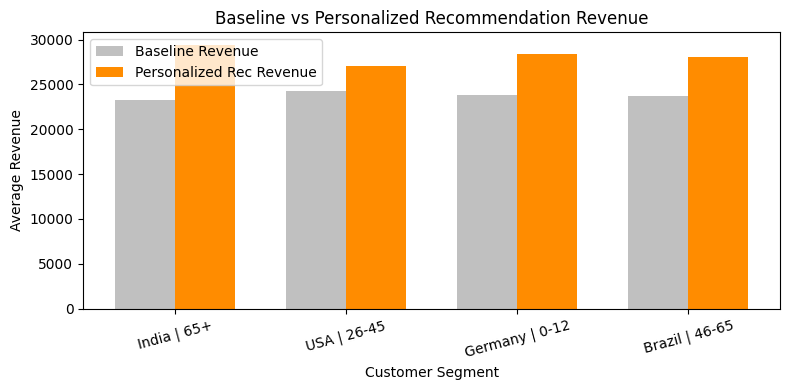

In [13]:
# visualize baseline vs personalized recommendation revenue across segments
x = np.arange(len(impact_df))
width = 0.35

plt.figure(figsize=(8, 4))
plt.bar(x - width / 2, impact_df['baseline_revenue'], width, label='Baseline Revenue', color='silver')
plt.bar(x + width / 2, impact_df['recommended_revenue'], width, label='Personalized Rec Revenue', color='darkorange')
plt.title('Baseline vs Personalized Recommendation Revenue')
plt.xlabel('Customer Segment')
plt.ylabel('Average Revenue')
plt.xticks(x, impact_df['segment'], rotation=15)
plt.legend()
plt.tight_layout()
plt.show()